# Fase 5: Modelado Predictivo de la Demanda (Objetivo 3)

**Pregunta:** ¿qué tan predecible es la demanda de pasajeros de los buses intermunicipales a partir de la temporalidad (día, mes, festivos, temporadas) y del comportamiento reciente de cada ruta?

Corresponde a las fases de **modelado y evaluación** de CRISP-DM. Si los modelos superan a una línea base ingenua, la demanda es predecible y las terminales podrían programar los despachos según la demanda esperada, reduciendo la subocupación y las emisiones.

### Decisiones de diseño (ver bitácora)
| Decisión | Elección | Justificación |
|---|---|---|
| Granularidad | Ruta × día | 5,3 millones de despachos son inmanejables para 10 modelos con optimización; la programación de flota se decide por día y ruta |
| Rutas | Las `N_RUTAS` de mayor demanda entre las que operan al menos el 80 % de los días | Series regulares y representativas; se reporta su cobertura de pasajeros |
| Variable objetivo | Pasajeros por ruta y día (transformación log1p para entrenar) | La demanda determina cuántos buses despachar; log1p reduce la asimetría |
| Diciembre de 2025 y días truncados | Excluidos como objetivo | Datos incompletos en la fuente (desde octubre de 2025, el último día de cada mes llega parcial) |
| Prueba | Febrero y marzo de 2026, separados antes de cualquier transformación | Evaluación honesta sobre el futuro |
| Validación | Cortes temporales por fecha (`TimeSeriesSplit`, 5 cortes) | Respeta el orden del tiempo; las fechas no se mezclan entre entrenamiento y validación |
| Preprocesamiento | Todo dentro de un `Pipeline` (imputación, escalado, codificación) | Evita fuga de información entre particiones |
| Clases | No aplica balanceo | Es un problema de regresión |

In [1]:
import os, time, json, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import optuna
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURACIÓN -----------------------------
SEED = 42
MODO_RAPIDO = False        # True: pocas pruebas, solo para verificar que el cuaderno corre (NO reportar)
N_TRIALS = 3 if MODO_RAPIDO else 15   # pruebas de Optuna, iguales para todos los modelos
N_SPLITS = 5               # cortes de validación temporal
N_RUTAS = 100              # rutas de mayor demanda que se modelan
FECHA_PRUEBA = "2026-02-01"  # desde esta fecha: conjunto de prueba
MAX_MUESTRAS_SVR_KNN = 10_000  # SVR y KNN se entrenan con una submuestra (costo computacional)
# -------------------------------------------------------------------------

np.random.seed(SEED)
FIGS = Path("../results/figures"); FIGS.mkdir(parents=True, exist_ok=True)
TABS = Path("../results/tables");  TABS.mkdir(parents=True, exist_ok=True)
RES = Path("../results")
print(f"Modo rápido: {MODO_RAPIDO} | Pruebas por modelo: {N_TRIALS} | Cortes: {N_SPLITS} | Rutas: {N_RUTAS}")

Modo rápido: False | Pruebas por modelo: 15 | Cortes: 5 | Rutas: 100


## 1. Construcción del dataset ruta-día

In [2]:
cols = ["fecha_despacho", "codigo_origen", "codigo_destino", "nombre_origen", "nombre_destino",
        "nombre_dept_origen", "distancia_km", "pasajeros", "despachos"]
d = pd.read_parquet("../datos/despachos_enriquecidos.parquet", columns=cols)
d["fecha"] = pd.to_datetime(d["fecha_despacho"]).dt.normalize()
d["ruta"] = d["codigo_origen"].astype(str) + "-" + d["codigo_destino"].astype(str)
pasajeros_totales = d["pasajeros"].sum()

# Días incompletos en la fuente: total nacional < 50 % de la mediana móvil de 15 días y que no sea festivo.
# (Desde octubre de 2025 el último día de cada mes llega truncado; se tratan como faltantes.)
total_dia = d.groupby("fecha")["pasajeros"].sum()
razon = total_dia / total_dia.rolling(15, center=True, min_periods=5).median()
festivos_co = set(pd.to_datetime(list(holidays.Colombia(years=[2025, 2026]).keys())))
dias_incompletos = razon[(razon < 0.5) & ~razon.index.isin(festivos_co)]
(dias_incompletos.round(3).rename("razon_vs_mediana_movil").rename_axis("fecha").reset_index()
 .to_csv(TABS / "fase5_00_dias_incompletos.csv", index=False))
print("Días incompletos excluidos como objetivo:", [f.date().isoformat() for f in dias_incompletos.index])

diario = (d.groupby(["ruta", "fecha"], observed=True)
          .agg(pasajeros=("pasajeros", "sum"), buses=("despachos", "sum")).reset_index())
atributos = (d.groupby("ruta", observed=True)
             .agg(origen=("nombre_origen", "first"), destino=("nombre_destino", "first"),
                  dept_origen=("nombre_dept_origen", "first"), distancia_km=("distancia_km", "first"))
             .reset_index())
del d

# Diciembre de 2025 y días incompletos: datos parciales en la fuente -> no se usan como objetivo
es_diciembre = diario["fecha"].dt.to_period("M") == "2025-12"
diario = diario[~es_diciembre & ~diario["fecha"].isin(dias_incompletos.index)]
dias_disponibles = diario["fecha"].nunique()

resumen_rutas = diario.groupby("ruta").agg(dias=("fecha", "size"), pasajeros=("pasajeros", "sum")).reset_index()
regulares = resumen_rutas[resumen_rutas["dias"] >= 0.8 * dias_disponibles]
seleccion = regulares.sort_values("pasajeros", ascending=False).head(N_RUTAS)
seleccion = seleccion.merge(atributos, on="ruta")
seleccion.to_csv(TABS / "fase5_01_rutas_modeladas.csv", index=False)

cobertura = seleccion["pasajeros"].sum() / pasajeros_totales * 100
display(Markdown(f"""
- Rutas regulares (operan al menos el 80 % de los {dias_disponibles} días con datos): **{len(regulares):,}**
- Rutas modeladas: **{len(seleccion)}**, que transportan el **{cobertura:.1f} %** de los pasajeros del periodo.
"""))

Días incompletos excluidos como objetivo: ['2025-10-31', '2025-12-14', '2025-12-15', '2025-12-16', '2025-12-31', '2026-01-31', '2026-02-28', '2026-03-31']



- Rutas regulares (operan al menos el 80 % de los 420 días con datos): **788**
- Rutas modeladas: **100**, que transportan el **62.2 %** de los pasajeros del periodo.


## 2. Ingeniería de características

Los rezagos y las ventanas móviles se calculan **solo con días anteriores** (desplazamiento de un día), así que no usan información del día que se predice. Los días sin registro quedan como faltantes y se imputan dentro del `Pipeline` con la mediana del entrenamiento.

In [3]:
ingenieria = pd.DataFrame([
    ("dia_semana", "Día de la semana (0 = lunes)", "Calendario", "Base", "Patrón semanal de la demanda"),
    ("mes", "Mes del año (1-12)", "Calendario", "Base", "Estacionalidad anual"),
    ("dia_mes", "Día del mes (1-31)", "Calendario", "Base", "Efectos de inicio y fin de mes"),
    ("distancia_km", "Distancia por carretera de la ruta (OSRM)", "Dominio", "Base", "Rutas largas y cortas tienen demandas distintas"),
    ("dept_origen", "Departamento de origen (one-hot)", "Dominio", "Base", "Diferencias regionales"),
    ("es_fin_semana", "1 si es sábado o domingo", "Calendario", "Ingeniería", "Viajes de descanso"),
    ("es_festivo", "1 si es festivo en Colombia (librería holidays)", "Calendario", "Ingeniería", "Puentes festivos"),
    ("vispera_festivo", "1 si el día siguiente es festivo", "Calendario", "Ingeniería", "Salidas antes del puente"),
    ("post_festivo", "1 si el día anterior fue festivo", "Calendario", "Ingeniería", "Regresos después del puente"),
    ("dia_pago", "1 si el día del mes es 1, 2, 15, 16, 30 o 31", "Dominio", "Ingeniería", "Quincenas: mayor capacidad de gasto"),
    ("vacaciones", "1 entre 15-jun y 15-jul, y entre 15-dic y 15-ene", "Dominio", "Ingeniería", "Temporada alta escolar"),
    ("lag_1", "Pasajeros de la ruta el día anterior", "Rezago", "Ingeniería", "Inercia de corto plazo"),
    ("lag_7", "Pasajeros de la ruta hace 7 días", "Rezago", "Ingeniería", "Mismo día de la semana anterior"),
    ("lag_14", "Pasajeros de la ruta hace 14 días", "Rezago", "Ingeniería", "Patrón semanal más estable"),
    ("media_7", "Media de los 7 días anteriores", "Ventana móvil", "Ingeniería", "Nivel reciente de la ruta"),
    ("media_28", "Media de los 28 días anteriores", "Ventana móvil", "Ingeniería", "Nivel mensual de la ruta"),
    ("std_7", "Desviación estándar de los 7 días anteriores", "Ventana móvil", "Ingeniería", "Volatilidad reciente"),
    ("media_mismo_dia_3s", "Media de lag_7, lag_14 y lag_21", "Ventana móvil", "Ingeniería", "Nivel típico de ese día de la semana"),
], columns=["variable", "formula", "tipo", "conjunto", "justificacion"])
ingenieria.to_csv(TABS / "fase5_02_ingenieria_caracteristicas.csv", index=False)
display(ingenieria)

,variable,formula,tipo,conjunto,justificacion
0,dia_semana,Día de la semana (0 = lunes),Calendario,Base,Patrón semanal de la demanda
1,mes,Mes del año (1-12),Calendario,Base,Estacionalidad anual
2,dia_mes,Día del mes (1-31),Calendario,Base,Efectos de inicio y fin de mes
3,distancia_km,Distancia por carretera de la ruta (OSRM),Dominio,Base,Rutas largas y cortas tienen demandas distintas
4,dept_origen,Departamento de origen (one-hot),Dominio,Base,Diferencias regionales
5,es_fin_semana,1 si es sábado o domingo,Calendario,Ingeniería,Viajes de descanso
6,es_festivo,1 si es festivo en Colombia (librería holidays),Calendario,Ingeniería,Puentes festivos
7,vispera_festivo,1 si el día siguiente es festivo,Calendario,Ingeniería,Salidas antes del puente
8,post_festivo,1 si el día anterior fue festivo,Calendario,Ingeniería,Regresos después del puente
9,dia_pago,"1 si el día del mes es 1, 2, 15, 16, 30 o 31",Dominio,Ingeniería,Quincenas: mayor capacidad de gasto


In [4]:
# Panel completo ruta x fecha (incluye diciembre como faltante para no "saltar" días en los rezagos)
fechas = pd.date_range(diario["fecha"].min(), diario["fecha"].max(), freq="D")
rutas = seleccion["ruta"].tolist()
panel = (pd.MultiIndex.from_product([rutas, fechas], names=["ruta", "fecha"]).to_frame(index=False)
         .merge(diario[diario["ruta"].isin(rutas)], on=["ruta", "fecha"], how="left"))
panel = panel.sort_values(["ruta", "fecha"]).reset_index(drop=True)

g = panel.groupby("ruta")["pasajeros"]
previo = g.shift(1)
panel["lag_1"] = previo
panel["lag_7"] = g.shift(7)
panel["lag_14"] = g.shift(14)
lag_21 = g.shift(21)
panel["media_7"] = previo.groupby(panel["ruta"]).transform(lambda s: s.rolling(7, min_periods=3).mean())
panel["media_28"] = previo.groupby(panel["ruta"]).transform(lambda s: s.rolling(28, min_periods=7).mean())
panel["std_7"] = previo.groupby(panel["ruta"]).transform(lambda s: s.rolling(7, min_periods=3).std())
panel["media_mismo_dia_3s"] = pd.concat([panel["lag_7"], panel["lag_14"], lag_21], axis=1).mean(axis=1)

# Calendario y dominio
festivos = set(pd.to_datetime(list(holidays.Colombia(years=[2025, 2026]).keys())))
f = panel["fecha"]
panel["dia_semana"] = f.dt.dayofweek
panel["mes"] = f.dt.month
panel["dia_mes"] = f.dt.day
panel["es_fin_semana"] = (panel["dia_semana"] >= 5).astype(int)
panel["es_festivo"] = f.isin(festivos).astype(int)
panel["vispera_festivo"] = (f + pd.Timedelta(days=1)).isin(festivos).astype(int)
panel["post_festivo"] = (f - pd.Timedelta(days=1)).isin(festivos).astype(int)
panel["dia_pago"] = panel["dia_mes"].isin([1, 2, 15, 16, 30, 31]).astype(int)
panel["vacaciones"] = (((panel["mes"] == 6) & (panel["dia_mes"] >= 15)) | ((panel["mes"] == 7) & (panel["dia_mes"] <= 15)) |
                       ((panel["mes"] == 12) & (panel["dia_mes"] >= 15)) | ((panel["mes"] == 1) & (panel["dia_mes"] <= 15))).astype(int)
panel = panel.merge(seleccion[["ruta", "distancia_km", "dept_origen"]], on="ruta", how="left")

# Filas válidas para modelar: día observado, fuera de diciembre y después del primer mes (calentamiento de rezagos)
modelo_df = panel[panel["pasajeros"].notna()
                  & (panel["fecha"].dt.to_period("M") != "2025-12")
                  & (panel["fecha"] >= panel["fecha"].min() + pd.Timedelta(days=28))].reset_index(drop=True)
print(f"Filas ruta-día para modelar: {len(modelo_df):,} | Periodo: {modelo_df.fecha.min().date()} a {modelo_df.fecha.max().date()}")

Filas ruta-día para modelar: 38,996 | Periodo: 2025-01-29 a 2026-03-30


## 3. Partición: el conjunto de prueba se separa antes de cualquier transformación

In [5]:
NUM_BASE = ["dia_semana", "mes", "dia_mes", "distancia_km"]
CAT = ["dept_origen"]
NUM_ING = ["es_fin_semana", "es_festivo", "vispera_festivo", "post_festivo", "dia_pago", "vacaciones",
           "lag_1", "lag_7", "lag_14", "media_7", "media_28", "std_7", "media_mismo_dia_3s"]

es_prueba = modelo_df["fecha"] >= pd.Timestamp(FECHA_PRUEBA)
train = modelo_df[~es_prueba].sort_values(["fecha", "ruta"]).reset_index(drop=True)
test = modelo_df[es_prueba].sort_values(["fecha", "ruta"]).reset_index(drop=True)
y_train, y_test = train["pasajeros"].to_numpy(), test["pasajeros"].to_numpy()

particion = pd.DataFrame({
    "conjunto": ["Entrenamiento y validación", "Prueba"],
    "desde": [train.fecha.min().date(), test.fecha.min().date()],
    "hasta": [train.fecha.max().date(), test.fecha.max().date()],
    "filas": [len(train), len(test)],
})
particion.to_csv(TABS / "fase5_03_particion.csv", index=False)
display(particion)

# Cortes temporales por FECHA: una misma fecha nunca queda a la vez en entrenamiento y validación
fechas_unicas = np.sort(train["fecha"].unique())
CORTES = []
for i, (tr_d, va_d) in enumerate(TimeSeriesSplit(n_splits=N_SPLITS).split(fechas_unicas), start=1):
    tr = np.where(train["fecha"].isin(fechas_unicas[tr_d]))[0]
    va = np.where(train["fecha"].isin(fechas_unicas[va_d]))[0]
    CORTES.append((tr, va))
    print(f"Corte {i}: entrena hasta {pd.Timestamp(fechas_unicas[tr_d][-1]).date()} ({len(tr):,} filas) | "
          f"valida {pd.Timestamp(fechas_unicas[va_d][0]).date()} a {pd.Timestamp(fechas_unicas[va_d][-1]).date()} ({len(va):,} filas)")

,conjunto,desde,hasta,filas
0,Entrenamiento y validación,2025-01-29,2026-01-30,33387
1,Prueba,2026-02-01,2026-03-30,5609


Corte 1: entrena hasta 2025-03-29 (5,991 filas) | valida 2025-03-30 a 2025-05-23 (5,496 filas)
Corte 2: entrena hasta 2025-05-23 (11,487 filas) | valida 2025-05-24 a 2025-07-17 (5,499 filas)
Corte 3: entrena hasta 2025-07-17 (16,986 filas) | valida 2025-07-18 a 2025-09-10 (5,487 filas)
Corte 4: entrena hasta 2025-09-10 (22,473 filas) | valida 2025-09-11 a 2025-11-05 (5,497 filas)
Corte 5: entrena hasta 2025-11-05 (27,970 filas) | valida 2025-11-06 a 2026-01-30 (5,417 filas)


## 4. Selección de variables por información mutua

Se calcula sobre el conjunto de entrenamiento (nunca sobre prueba). Se conservan las variables con información mutua de al menos 0,01 con la variable objetivo (en escala log1p).

In [6]:
cand = NUM_BASE + NUM_ING
muestra = train.sample(n=min(30_000, len(train)), random_state=SEED)
X_mi = muestra[cand].fillna(muestra[cand].median())
X_mi["dept_origen"] = muestra["dept_origen"].astype("category").cat.codes
discretas = [c in ["dia_semana", "mes", "dia_mes", "es_fin_semana", "es_festivo", "vispera_festivo",
                   "post_festivo", "dia_pago", "vacaciones", "dept_origen"] for c in X_mi.columns]
mi = mutual_info_regression(X_mi, np.log1p(muestra["pasajeros"]), discrete_features=discretas, random_state=SEED)
tabla_mi = (pd.DataFrame({"variable": X_mi.columns, "informacion_mutua": mi})
            .sort_values("informacion_mutua", ascending=False).reset_index(drop=True))
UMBRAL_MI = 0.01
tabla_mi["seleccionada"] = tabla_mi["informacion_mutua"] >= UMBRAL_MI
tabla_mi.round(4).to_csv(TABS / "fase5_04_seleccion_informacion_mutua.csv", index=False)
display(tabla_mi.round(4))

sel = set(tabla_mi.loc[tabla_mi["seleccionada"], "variable"])
NUM_SEL = [c for c in cand if c in sel]
CAT_SEL = [c for c in CAT if c in sel]
display(Markdown(f"**Variables seleccionadas ({len(NUM_SEL) + len(CAT_SEL)}):** {', '.join(NUM_SEL + CAT_SEL)}  \n"
                 f"**Descartadas:** {', '.join(tabla_mi.loc[~tabla_mi['seleccionada'], 'variable']) or 'ninguna'}"))

,variable,informacion_mutua,seleccionada
0,media_7,0.9192,True
1,lag_1,0.8703,True
2,media_28,0.8349,True
3,media_mismo_dia_3s,0.8110,True
4,distancia_km,0.8008,True
5,lag_7,0.7440,True
6,lag_14,0.6722,True
7,std_7,0.3181,True
8,dept_origen,0.2406,True
9,mes,0.0152,True


**Variables seleccionadas (11):** mes, distancia_km, vacaciones, lag_1, lag_7, lag_14, media_7, media_28, std_7, media_mismo_dia_3s, dept_origen  
**Descartadas:** dia_semana, es_festivo, dia_mes, es_fin_semana, dia_pago, vispera_festivo, post_festivo

## 5. Utilidades: pipeline, métricas y validación

In [7]:
LOG_MAX = float(np.log1p(y_train.max() * 3))  # tope de las predicciones: 3 veces el máximo observado en entrenamiento

class Submuestra(BaseEstimator, RegressorMixin):
    """Entrena el estimador con una submuestra aleatoria (para SVR y KNN, de costo cuadrático)."""
    def __init__(self, estimator=None, max_muestras=10_000, random_state=SEED):
        self.estimator = estimator; self.max_muestras = max_muestras; self.random_state = random_state
    def fit(self, X, y):
        n = X.shape[0]
        idx = (np.random.default_rng(self.random_state).choice(n, self.max_muestras, replace=False)
               if n > self.max_muestras else np.arange(n))
        self.est_ = clone(self.estimator).fit(X[idx], np.asarray(y)[idx]); return self
    def predict(self, X):
        return self.est_.predict(X)

def inversa_log(z):
    """Inversa de log1p con tope, para evitar desbordes de modelos inestables (p. ej. redes en sus primeras pruebas)."""
    return np.expm1(np.clip(z, 0, LOG_MAX))

def construir(estimador, num, cat):
    """Pipeline completo: imputación + escalado + one-hot + modelo, con objetivo en log1p."""
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return TransformedTargetRegressor(regressor=Pipeline([("prep", prep), ("modelo", estimador)]),
                                      func=np.log1p, inverse_func=inversa_log, check_inverse=False)

def metricas(y, p):
    p = np.clip(np.nan_to_num(p, nan=0.0, posinf=np.expm1(LOG_MAX)), 0, None)
    pos = y > 0
    return {"RMSE": float(np.sqrt(mean_squared_error(y, p))), "MAE": float(mean_absolute_error(y, p)),
            "MAPE": float(np.mean(np.abs(y[pos] - p[pos]) / y[pos]) * 100), "R2": float(r2_score(y, p))}

def evaluar_cv(fabrica, X, y):
    """Entrena y valida en cada corte temporal. Devuelve métricas por corte y tiempo medio de entrenamiento."""
    filas, tiempos = [], []
    for k, (tr, va) in enumerate(CORTES, start=1):
        m = fabrica(); t0 = time.time()
        m.fit(X.iloc[tr], y[tr]); tiempos.append(time.time() - t0)
        filas.append({"corte": k, **metricas(y[va], m.predict(X.iloc[va]))})
    return pd.DataFrame(filas), float(np.mean(tiempos))

print("Utilidades listas.")

Utilidades listas.


## 6. Batería de modelos y optimización de hiperparámetros con Optuna

In [8]:
ESPACIOS = {
    "Ridge": "alpha: log [1e-3, 1e3]",
    "Lasso": "alpha: log [1e-4, 1]",
    "KNN": "n_neighbors: [3, 50]; weights: uniform | distance",
    "SVR": "C: log [0.1, 100]; epsilon: [0.01, 0.5]",
    "Árbol de decisión": "max_depth: [3, 20]; min_samples_leaf: [1, 100]",
    "Random Forest": "n_estimators: [50, 300]; max_depth: [5, 25]; min_samples_leaf: [1, 50]; max_features: [0.3, 1.0]",
    "LightGBM": "n_estimators: [100, 800]; learning_rate: log [0.01, 0.2]; num_leaves: [15, 255]; min_child_samples: [5, 100]; subsample: [0.6, 1]; colsample_bytree: [0.6, 1]",
    "MLP": "capas: 64 | 128 | 64-32 | 128-64; alpha: log [1e-5, 1e-1]; learning_rate_init: log [1e-4, 1e-2]",
}

def estimador(nombre, p):
    if nombre == "Regresión lineal": return LinearRegression()
    if nombre == "Ridge": return Ridge(alpha=p["alpha"], random_state=SEED)
    if nombre == "Lasso": return Lasso(alpha=p["alpha"], random_state=SEED, max_iter=5000)
    if nombre == "KNN": return Submuestra(KNeighborsRegressor(n_neighbors=p["n_neighbors"], weights=p["weights"]), MAX_MUESTRAS_SVR_KNN)
    if nombre == "SVR": return Submuestra(SVR(C=p["C"], epsilon=p["epsilon"]), MAX_MUESTRAS_SVR_KNN)
    if nombre == "Árbol de decisión": return DecisionTreeRegressor(max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"], random_state=SEED)
    if nombre == "Random Forest": return RandomForestRegressor(n_estimators=p["n_estimators"], max_depth=p["max_depth"],
                                                               min_samples_leaf=p["min_samples_leaf"], max_features=p["max_features"],
                                                               n_jobs=-1, random_state=SEED)
    if nombre == "LightGBM": return LGBMRegressor(n_estimators=p["n_estimators"], learning_rate=p["learning_rate"], num_leaves=p["num_leaves"],
                                                  min_child_samples=p["min_child_samples"], subsample=p["subsample"], subsample_freq=1,
                                                  colsample_bytree=p["colsample_bytree"], random_state=SEED, verbose=-1)
    if nombre == "MLP":
        capas = {"64": (64,), "128": (128,), "64-32": (64, 32), "128-64": (128, 64)}[p["capas"]]
        return MLPRegressor(hidden_layer_sizes=capas, alpha=p["alpha"], learning_rate_init=p["learning_rate_init"],
                            early_stopping=True, max_iter=200, random_state=SEED)

def sugerir(nombre, t):
    if nombre == "Ridge": return {"alpha": t.suggest_float("alpha", 1e-3, 1e3, log=True)}
    if nombre == "Lasso": return {"alpha": t.suggest_float("alpha", 1e-4, 1, log=True)}
    if nombre == "KNN": return {"n_neighbors": t.suggest_int("n_neighbors", 3, 50), "weights": t.suggest_categorical("weights", ["uniform", "distance"])}
    if nombre == "SVR": return {"C": t.suggest_float("C", 0.1, 100, log=True), "epsilon": t.suggest_float("epsilon", 0.01, 0.5)}
    if nombre == "Árbol de decisión": return {"max_depth": t.suggest_int("max_depth", 3, 20), "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 100)}
    if nombre == "Random Forest": return {"n_estimators": t.suggest_int("n_estimators", 50, 300), "max_depth": t.suggest_int("max_depth", 5, 25),
                                          "min_samples_leaf": t.suggest_int("min_samples_leaf", 1, 50), "max_features": t.suggest_float("max_features", 0.3, 1.0)}
    if nombre == "LightGBM": return {"n_estimators": t.suggest_int("n_estimators", 100, 800), "learning_rate": t.suggest_float("learning_rate", 0.01, 0.2, log=True),
                                     "num_leaves": t.suggest_int("num_leaves", 15, 255), "min_child_samples": t.suggest_int("min_child_samples", 5, 100),
                                     "subsample": t.suggest_float("subsample", 0.6, 1.0), "colsample_bytree": t.suggest_float("colsample_bytree", 0.6, 1.0)}
    if nombre == "MLP": return {"capas": t.suggest_categorical("capas", ["64", "128", "64-32", "128-64"]),
                                "alpha": t.suggest_float("alpha", 1e-5, 1e-1, log=True),
                                "learning_rate_init": t.suggest_float("learning_rate_init", 1e-4, 1e-2, log=True)}

X_train, X_test = train[NUM_SEL + CAT_SEL], test[NUM_SEL + CAT_SEL]
mejores, historial_trials = {}, []

for nombre in ESPACIOS:
    t0 = time.time()
    def objetivo(trial):
        p = sugerir(nombre, trial)
        cv, _ = evaluar_cv(lambda: construir(estimador(nombre, p), NUM_SEL, CAT_SEL), X_train, y_train)
        return cv["RMSE"].mean()
    estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    estudio.optimize(objetivo, n_trials=N_TRIALS)
    mejores[nombre] = estudio.best_params
    for tr in estudio.trials:
        historial_trials.append({"modelo": nombre, "prueba": tr.number, "rmse_cv": tr.value, "parametros": json.dumps(tr.params)})
    print(f"{nombre:20s} RMSE CV = {estudio.best_value:9.2f} | {time.time() - t0:6.0f} s | {estudio.best_params}")

mejores["Regresión lineal"] = {}
pd.DataFrame(historial_trials).to_csv(TABS / "fase5_05_optuna_pruebas.csv", index=False)
hiper = pd.DataFrame([{"modelo": m, "espacio_de_busqueda": ESPACIOS.get(m, "Sin hiperparámetros"),
                       "mejores_valores": json.dumps(mejores[m])} for m in ["Regresión lineal"] + list(ESPACIOS)])
hiper.to_csv(TABS / "fase5_06_hiperparametros.csv", index=False)
display(hiper)

Ridge                RMSE CV =   1042.49 |      5 s | {'alpha': 879.4080529754356}
Lasso                RMSE CV =    580.25 |     45 s | {'alpha': 0.26944991666882157}
KNN                  RMSE CV =    393.50 |     16 s | {'n_neighbors': 32, 'weights': 'distance'}
SVR                  RMSE CV =    475.27 |    435 s | {'C': 0.22057320053419874, 'epsilon': 0.04062806464753837}
Árbol de decisión    RMSE CV =    384.21 |      9 s | {'max_depth': 10, 'min_samples_leaf': 30}
Random Forest        RMSE CV =    371.73 |    113 s | {'n_estimators': 139, 'max_depth': 19, 'min_samples_leaf': 17, 'max_features': 0.907384162843224}
MLP                  RMSE CV =    684.86 |    293 s | {'capas': '64', 'alpha': 0.00020320453957116085, 'learning_rate_init': 0.0018106139717754329}


,modelo,espacio_de_busqueda,mejores_valores
0,Regresión lineal,Sin hiperparámetros,{}
1,Ridge,"alpha: log [1e-3, 1e3]","{""alpha"": 879.4080529754356}"
2,Lasso,"alpha: log [1e-4, 1]","{""alpha"": 0.26944991666882157}"
3,KNN,"n_neighbors: [3, 50]; weights: uniform | distance","{""n_neighbors"": 32, ""weights"": ""distance""}"
4,SVR,"C: log [0.1, 100]; epsilon: [0.01, 0.5]","{""C"": 0.22057320053419874, ""epsilon"": 0.040628..."
5,Árbol de decisión,"max_depth: [3, 20]; min_samples_leaf: [1, 100]","{""max_depth"": 10, ""min_samples_leaf"": 30}"
6,Random Forest,"n_estimators: [50, 300]; max_depth: [5, 25]; m...","{""n_estimators"": 139, ""max_depth"": 19, ""min_sa..."
7,LightGBM,"n_estimators: [100, 800]; learning_rate: log [...","{""n_estimators"": 683, ""learning_rate"": 0.01889..."
8,MLP,capas: 64 | 128 | 64-32 | 128-64; alpha: log [...,"{""capas"": ""64"", ""alpha"": 0.0002032045395711608..."


### Red neuronal recurrente (GRU)

Los datos son secuenciales, por lo que se incluye una red **GRU**. Recibe la secuencia de los 28 días anteriores de cada ruta (en log1p) y las variables de calendario del día a predecir. Se optimiza con el mismo número de pruebas de Optuna y los mismos cortes temporales.

In [9]:
import tensorflow as tf
import keras
tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)

VENTANA = 28
CAL_GRU = ["es_fin_semana", "es_festivo", "vispera_festivo", "post_festivo", "dia_pago", "vacaciones"]

def secuencias(df):
    """Para cada fila (ruta, fecha): los 28 días previos de pasajeros (log1p, faltantes = 0) desde el panel completo."""
    piv = panel.pivot(index="fecha", columns="ruta", values="pasajeros")
    arr = np.log1p(piv.fillna(0).to_numpy()); pos_f = {f: i for i, f in enumerate(piv.index)}; pos_r = {r: j for j, r in enumerate(piv.columns)}
    out = np.zeros((len(df), VENTANA, 1), dtype="float32")
    for k, (r, f) in enumerate(zip(df["ruta"], df["fecha"])):
        i, j = pos_f[f], pos_r[r]
        out[k, :, 0] = arr[i - VENTANA:i, j]
    return out

def calendario(df):
    c = df[CAL_GRU].to_numpy(dtype="float32")
    dsem = df["dia_semana"].to_numpy(); mes = df["mes"].to_numpy()
    ciclicas = np.column_stack([np.sin(2 * np.pi * dsem / 7), np.cos(2 * np.pi * dsem / 7),
                                np.sin(2 * np.pi * mes / 12), np.cos(2 * np.pi * mes / 12)]).astype("float32")
    return np.hstack([c, ciclicas, np.log1p(df[["distancia_km"]].to_numpy(dtype="float32"))])

SEQ_TR, CAL_TR = secuencias(train), calendario(train)
SEQ_TE, CAL_TE = secuencias(test), calendario(test)
EPOCAS = 2 if MODO_RAPIDO else 12

class GRURegresor:
    def __init__(self, unidades=32, dropout=0.1, lr=1e-3):
        self.unidades, self.dropout, self.lr = unidades, dropout, lr
    def fit(self, seq, cal, y):
        keras.utils.set_random_seed(SEED)
        self.mu, self.sd = cal.mean(0), cal.std(0) + 1e-6
        e_seq = keras.Input((VENTANA, 1)); e_cal = keras.Input((cal.shape[1],))
        h = keras.layers.GRU(self.unidades, dropout=self.dropout)(e_seq)
        h = keras.layers.Concatenate()([h, e_cal])
        h = keras.layers.Dense(32, activation="relu")(h)
        salida = keras.layers.Dense(1)(h)
        self.m = keras.Model([e_seq, e_cal], salida)
        self.m.compile(optimizer=keras.optimizers.Adam(self.lr), loss="mse")
        self.m.fit([seq, (cal - self.mu) / self.sd], np.log1p(y), epochs=EPOCAS, batch_size=512, verbose=0,
                   validation_split=0.1, callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
        return self
    def predict(self, seq, cal):
        return inversa_log(self.m.predict([seq, (cal - self.mu) / self.sd], verbose=0, batch_size=2048).ravel())

def cv_gru(p):
    filas, tiempos = [], []
    for k, (tr, va) in enumerate(CORTES, start=1):
        t0 = time.time(); m = GRURegresor(**p).fit(SEQ_TR[tr], CAL_TR[tr], y_train[tr]); tiempos.append(time.time() - t0)
        filas.append({"corte": k, **metricas(y_train[va], m.predict(SEQ_TR[va], CAL_TR[va]))})
    return pd.DataFrame(filas), float(np.mean(tiempos))

t0 = time.time()
estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudio.optimize(lambda t: cv_gru({"unidades": t.suggest_int("unidades", 16, 64), "dropout": t.suggest_float("dropout", 0.0, 0.3),
                                    "lr": t.suggest_float("lr", 1e-4, 1e-2, log=True)})[0]["RMSE"].mean(), n_trials=N_TRIALS)
mejores["GRU"] = estudio.best_params
ESPACIOS["GRU"] = "unidades: [16, 64]; dropout: [0, 0.3]; lr: log [1e-4, 1e-2]"
for tr in estudio.trials:
    historial_trials.append({"modelo": "GRU", "prueba": tr.number, "rmse_cv": tr.value, "parametros": json.dumps(tr.params)})
pd.DataFrame(historial_trials).to_csv(TABS / "fase5_05_optuna_pruebas.csv", index=False)
hiper = pd.concat([hiper, pd.DataFrame([{"modelo": "GRU", "espacio_de_busqueda": ESPACIOS["GRU"],
                                         "mejores_valores": json.dumps(mejores["GRU"])}])], ignore_index=True)
hiper.to_csv(TABS / "fase5_06_hiperparametros.csv", index=False)
print(f"GRU RMSE CV = {estudio.best_value:.2f} | {time.time() - t0:.0f} s | {estudio.best_params}")

GRU RMSE CV = 993.77 | 765 s | {'unidades': 35, 'dropout': 0.2493431385525267, 'lr': 0.0006437290330740571}


## 7. Evaluación: validación cruzada temporal y conjunto de prueba

In [ ]:
ORDEN = ["Línea base ingenua", "Regresión lineal", "Ridge", "Lasso", "KNN", "SVR",
         "Árbol de decisión", "Random Forest", "LightGBM", "MLP", "GRU"]
por_corte, resumen, predicciones = [], [], {}
fecha_corrida = datetime.now().strftime("%Y-%m-%d %H:%M")

def ingenua(df):
    """Línea base: los pasajeros del mismo día de la semana anterior (lag_7); si falta, la media de 28 días."""
    return df["lag_7"].fillna(df["media_28"]).fillna(np.median(y_train)).to_numpy()

for nombre in ORDEN:
    if nombre == "Línea base ingenua":
        cv = pd.DataFrame([{"corte": k, **metricas(y_train[va], ingenua(train.iloc[va]))} for k, (tr, va) in enumerate(CORTES, 1)])
        t_fit, pred = 0.0, ingenua(test)
    elif nombre == "GRU":
        cv, t_fit = cv_gru(mejores["GRU"])
        pred = GRURegresor(**mejores["GRU"]).fit(SEQ_TR, CAL_TR, y_train).predict(SEQ_TE, CAL_TE)
    else:
        fab = lambda: construir(estimador(nombre, mejores[nombre]), NUM_SEL, CAT_SEL)
        cv, t_fit = evaluar_cv(fab, X_train, y_train)
        pred = fab().fit(X_train, y_train).predict(X_test)
    predicciones[nombre] = np.clip(pred, 0, None)
    prueba = metricas(y_test, pred)
    por_corte.append(cv.assign(modelo=nombre))
    fila = {"modelo": nombre, "tiempo_entrenamiento_s": round(t_fit, 2)}
    for met in ["RMSE", "MAE", "MAPE", "R2"]:
        fila[f"{met}_cv_media"] = cv[met].mean(); fila[f"{met}_cv_desv"] = cv[met].std()
    fila.update({f"{met}_prueba": v for met, v in prueba.items()})
    resumen.append(fila)
    print(f"{nombre:20s} RMSE CV {cv.RMSE.mean():8.2f} ± {cv.RMSE.std():6.2f} | RMSE prueba {prueba['RMSE']:8.2f} | R2 prueba {prueba['R2']:.3f}")

metricas_particion = pd.concat(por_corte)[["modelo", "corte", "RMSE", "MAE", "MAPE", "R2"]]
metricas_particion.to_csv(TABS / "metricas_por_particion.csv", index=False)
tabla_modelos = pd.DataFrame(resumen).round(4)
tabla_modelos.to_csv(TABS / "fase5_07_comparacion_modelos.csv", index=False)

# Registro de experimentos: una fila por corrida y modelo
exp = pd.DataFrame([{"fecha": fecha_corrida, "modelo": r["modelo"], "parametros": json.dumps(mejores.get(r["modelo"], {})),
                     "semilla": SEED, "n_trials": N_TRIALS, "n_cortes": N_SPLITS, "n_rutas": N_RUTAS, "modo_rapido": MODO_RAPIDO,
                     "variables": "|".join(NUM_SEL + CAT_SEL), "rmse_cv": r["RMSE_cv_media"], "rmse_prueba": r["RMSE_prueba"],
                     "mae_prueba": r["MAE_prueba"], "mape_prueba": r["MAPE_prueba"], "r2_prueba": r["R2_prueba"]} for r in resumen])
ruta_exp = RES / "experiments.csv"
exp.to_csv(ruta_exp, mode="a", header=not ruta_exp.exists(), index=False)

columnas = ["modelo", "RMSE_cv_media", "RMSE_cv_desv", "MAE_cv_media", "MAPE_cv_media", "R2_cv_media",
            "RMSE_prueba", "MAE_prueba", "MAPE_prueba", "R2_prueba", "tiempo_entrenamiento_s"]
display(tabla_modelos[columnas])

Línea base ingenua   RMSE CV   499.64 ± 123.59 | RMSE prueba   354.67 | R2 prueba 0.813
Regresión lineal     RMSE CV  1118.25 ± 561.57 | RMSE prueba   555.93 | R2 prueba 0.540
Ridge                RMSE CV  1042.49 ± 535.31 | RMSE prueba   545.48 | R2 prueba 0.557
Lasso                RMSE CV   580.25 ±  55.58 | RMSE prueba   567.62 | R2 prueba 0.520
KNN                  RMSE CV   393.50 ±  77.31 | RMSE prueba   314.14 | R2 prueba 0.853
SVR                  RMSE CV   475.27 ± 138.95 | RMSE prueba   301.59 | R2 prueba 0.865
Árbol de decisión    RMSE CV   384.21 ±  77.38 | RMSE prueba   319.00 | R2 prueba 0.849
Random Forest        RMSE CV   371.73 ±  84.26 | RMSE prueba   304.97 | R2 prueba 0.862
LightGBM             RMSE CV   377.12 ±  76.62 | RMSE prueba   308.70 | R2 prueba 0.858
MLP                  RMSE CV   684.86 ± 399.87 | RMSE prueba   328.63 | R2 prueba 0.839


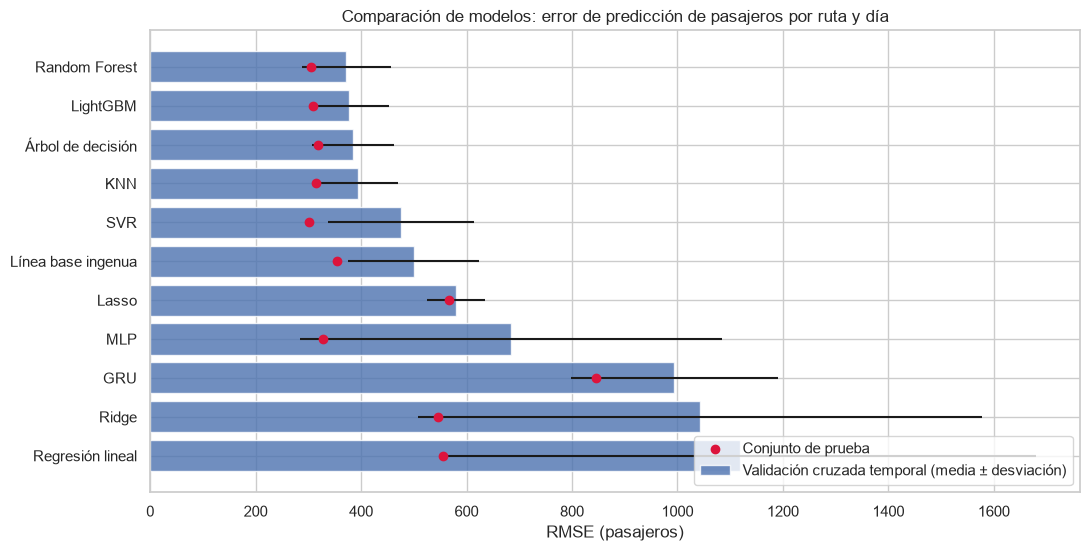

In [16]:
orden_fig = tabla_modelos.sort_values("RMSE_cv_media")
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(orden_fig["modelo"], orden_fig["RMSE_cv_media"], xerr=orden_fig["RMSE_cv_desv"], color="#4C72B0",
        alpha=0.8, label="Validación cruzada temporal (media ± desviación)")
ax.scatter(orden_fig["RMSE_prueba"], orden_fig["modelo"], color="crimson", zorder=3, label="Conjunto de prueba")
ax.invert_yaxis()
ax.set(title="Comparación de modelos: error de predicción de pasajeros por ruta y día",
       xlabel="RMSE (pasajeros)", ylabel="")
ax.legend(loc="lower right")
fig.savefig(FIGS / "fig_f5_01_comparacion_modelos.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación:** qué familia de modelos predice mejor, cuánto mejora frente a la línea base ingenua y si el error en prueba es coherente con el de validación (sin sobreajuste).

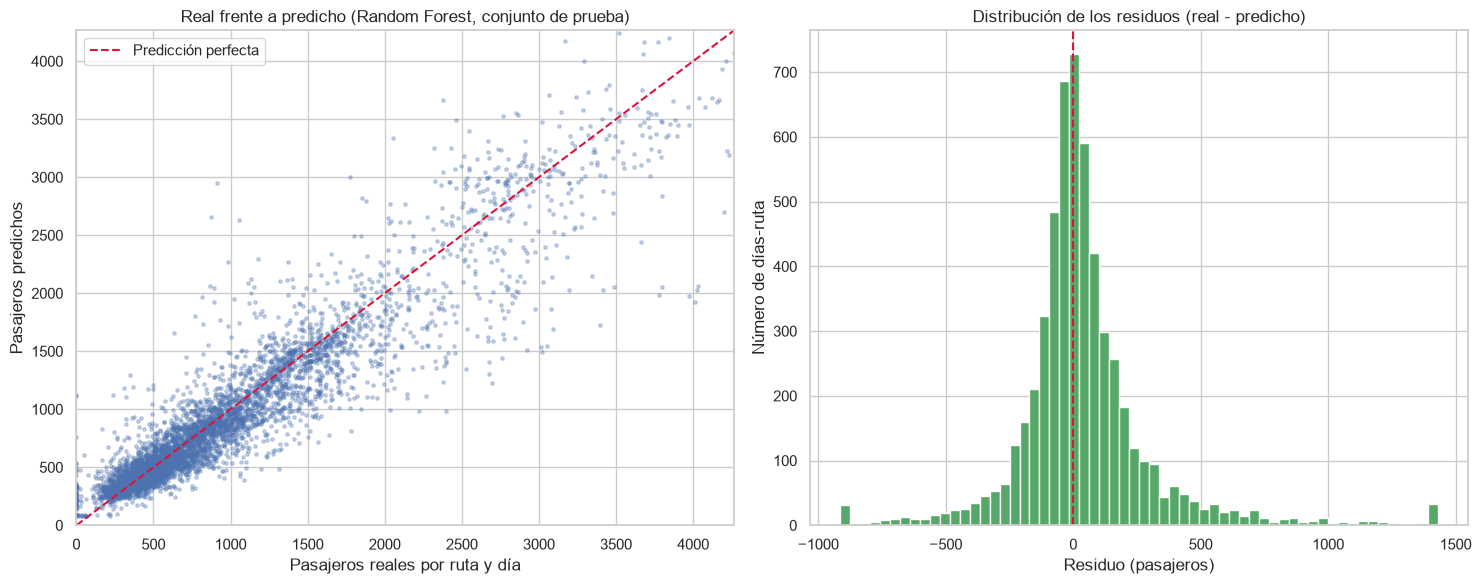

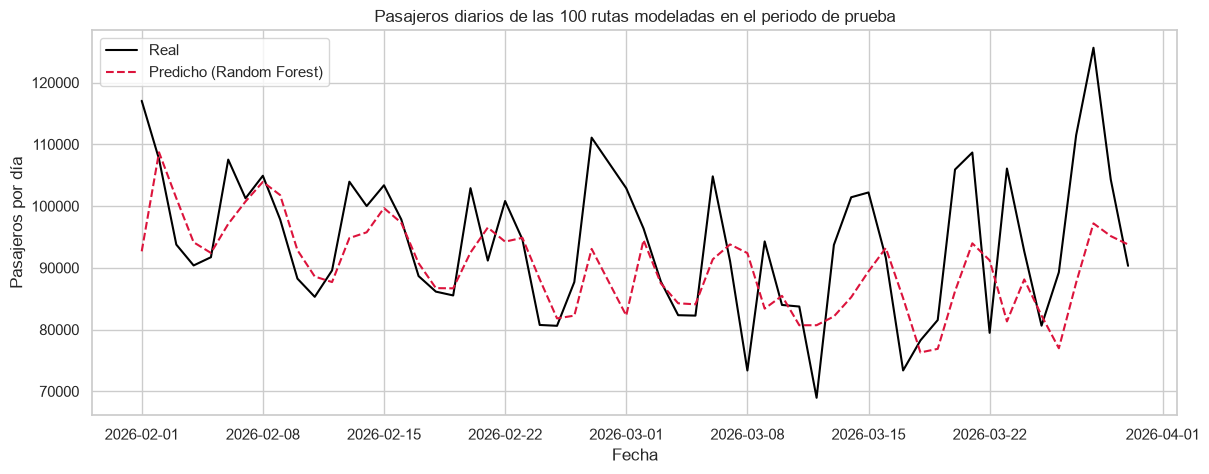

In [17]:
mejor = orden_fig.iloc[0]["modelo"]
p_mejor = predicciones[mejor]
residuos = y_test - p_mejor

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
lim = np.percentile(np.concatenate([y_test, p_mejor]), 99.5)
axes[0].scatter(y_test, p_mejor, s=6, alpha=0.3, color="#4C72B0")
axes[0].plot([0, lim], [0, lim], color="crimson", ls="--", label="Predicción perfecta")
axes[0].set(xlim=(0, lim), ylim=(0, lim), title=f"Real frente a predicho ({mejor}, conjunto de prueba)",
            xlabel="Pasajeros reales por ruta y día", ylabel="Pasajeros predichos")
axes[0].legend()
axes[1].hist(np.clip(residuos, *np.percentile(residuos, [0.5, 99.5])), bins=60, color="#55A868", edgecolor="white")
axes[1].axvline(0, color="crimson", ls="--")
axes[1].set(title="Distribución de los residuos (real - predicho)", xlabel="Residuo (pasajeros)", ylabel="Número de días-ruta")
plt.tight_layout()
fig.savefig(FIGS / "fig_f5_02_mejor_modelo_real_vs_predicho.png", dpi=200, bbox_inches="tight")
plt.show()

serie = test.assign(prediccion=p_mejor).groupby("fecha")[["pasajeros", "prediccion"]].sum()
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(serie.index, serie["pasajeros"], label="Real", color="black")
ax.plot(serie.index, serie["prediccion"], label=f"Predicho ({mejor})", color="crimson", ls="--")
ax.set(title=f"Pasajeros diarios de las {N_RUTAS} rutas modeladas en el periodo de prueba",
       xlabel="Fecha", ylabel="Pasajeros por día")
ax.legend()
fig.savefig(FIGS / "fig_f5_03_serie_prueba.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación:** si el modelo captura el patrón semanal y los picos de los festivos, y si los errores son simétricos (sin sesgo) o se concentran en los días de mayor demanda.

## 8. Importancia de las variables y ablación

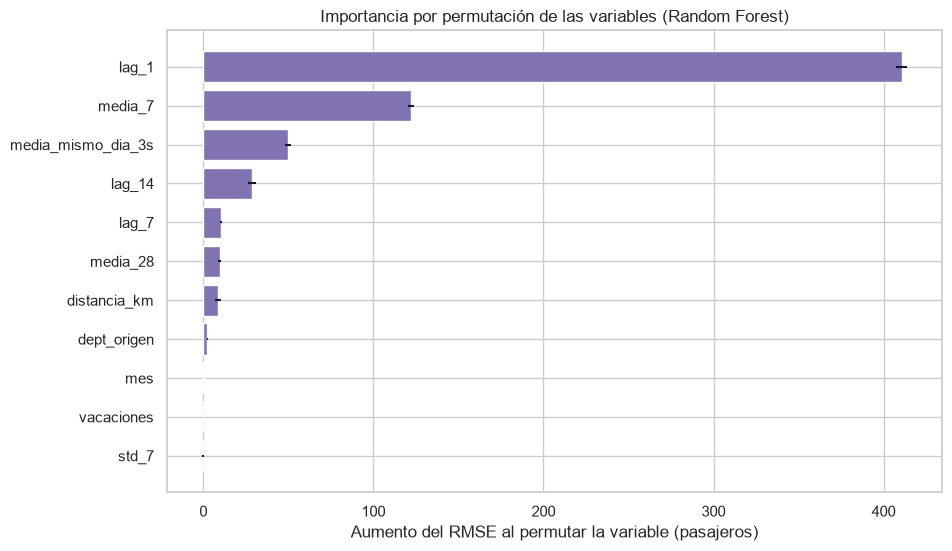

In [18]:
# Importancia por permutación sobre el conjunto de prueba (mejor modelo tabular; si el mejor es la GRU o la línea base, se usa LightGBM)
tabulares = [m for m in orden_fig["modelo"] if m not in ("GRU", "Línea base ingenua")]
modelo_imp = tabulares[0]
m_imp = construir(estimador(modelo_imp, mejores[modelo_imp]), NUM_SEL, CAT_SEL).fit(X_train, y_train)
idx = np.random.default_rng(SEED).choice(len(X_test), min(5_000, len(X_test)), replace=False)
imp = permutation_importance(m_imp, X_test.iloc[idx], y_test[idx], scoring="neg_root_mean_squared_error",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
tabla_imp = (pd.DataFrame({"variable": X_test.columns, "aumento_rmse": imp.importances_mean, "desv": imp.importances_std})
             .sort_values("aumento_rmse", ascending=False))
tabla_imp.round(3).to_csv(TABS / "fase5_08_importancia_variables.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
top = tabla_imp.head(15).iloc[::-1]
ax.barh(top["variable"], top["aumento_rmse"], xerr=top["desv"], color="#8172B2")
ax.set(title=f"Importancia por permutación de las variables ({modelo_imp})", xlabel="Aumento del RMSE al permutar la variable (pasajeros)")
fig.savefig(FIGS / "fig_f5_04_importancia_variables.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación:** qué pesa más en la predicción: el comportamiento reciente de la ruta (rezagos y medias) o el calendario (festivos, vacaciones, día de la semana). Esto responde directamente a la pregunta del objetivo 3.

In [19]:
# Ablación: el mejor modelo tabular con y sin las variables de ingeniería
base_num = [c for c in NUM_BASE]
abl = []
for etiqueta, num, cat in [("Sin ingeniería (solo variables base)", base_num, CAT),
                           ("Con ingeniería (variables seleccionadas)", NUM_SEL, CAT_SEL)]:
    fab = lambda: construir(estimador(modelo_imp, mejores[modelo_imp]), num, cat)
    cv, _ = evaluar_cv(fab, train[num + cat], y_train)
    pr = metricas(y_test, fab().fit(train[num + cat], y_train).predict(test[num + cat]))
    abl.append({"variante": etiqueta, "modelo": modelo_imp, "n_variables": len(num + cat),
                "RMSE_cv_media": cv.RMSE.mean(), "RMSE_cv_desv": cv.RMSE.std(), "R2_cv_media": cv.R2.mean(),
                "RMSE_prueba": pr["RMSE"], "MAE_prueba": pr["MAE"], "R2_prueba": pr["R2"]})
ablacion = pd.DataFrame(abl).round(4)
ablacion.to_csv(TABS / "fase5_09_ablacion.csv", index=False)
display(ablacion)

,variante,modelo,n_variables,RMSE_cv_media,RMSE_cv_desv,R2_cv_media,RMSE_prueba,MAE_prueba,R2_prueba
0,Sin ingeniería (solo variables base),Random Forest,5,449.8444,120.9407,0.7281,394.8705,241.5033,0.7679
1,Con ingeniería (variables seleccionadas),Random Forest,11,371.7292,84.2611,0.8142,304.9702,170.5861,0.8615


**Interpretación:** cuánto aportan las variables construidas. Si el error baja de forma clara, la ingeniería de características está justificada.

## 9. Hallazgos principales

In [20]:
b = tabla_modelos.set_index("modelo")
base_rmse = b.loc["Línea base ingenua", "RMSE_prueba"]
mejora = (1 - b.loc[mejor, "RMSE_prueba"] / base_rmse) * 100
mejora_abl = (1 - ablacion.iloc[1]["RMSE_prueba"] / ablacion.iloc[0]["RMSE_prueba"]) * 100
aviso = "\n> ⚠️ **Corrida en MODO RÁPIDO: estas cifras no deben reportarse.**" if MODO_RAPIDO else ""
display(Markdown(f"""{aviso}
- Mejor modelo en validación cruzada: **{mejor}**, con RMSE de **{b.loc[mejor, 'RMSE_cv_media']:.1f} ± {b.loc[mejor, 'RMSE_cv_desv']:.1f}** pasajeros por ruta y día.
- En el conjunto de prueba: RMSE **{b.loc[mejor, 'RMSE_prueba']:.1f}**, MAE **{b.loc[mejor, 'MAE_prueba']:.1f}**, MAPE **{b.loc[mejor, 'MAPE_prueba']:.1f} %** y R² **{b.loc[mejor, 'R2_prueba']:.3f}**.
- Frente a la línea base ingenua (mismo día de la semana anterior), el error en prueba {'baja' if mejora > 0 else 'sube'} un **{abs(mejora):.1f} %**.
- Las tres variables más importantes son: **{', '.join(tabla_imp['variable'].head(3))}**.
- La ingeniería de características {'reduce' if mejora_abl > 0 else 'aumenta'} el RMSE de prueba en **{abs(mejora_abl):.1f} %** ({modelo_imp}).
- Rutas modeladas: **{N_RUTAS}**, que concentran el **{cobertura:.1f} %** de los pasajeros del periodo.
"""))


- Mejor modelo en validación cruzada: **Random Forest**, con RMSE de **371.7 ± 84.3** pasajeros por ruta y día.
- En el conjunto de prueba: RMSE **305.0**, MAE **170.6**, MAPE **26.3 %** y R² **0.862**.
- Frente a la línea base ingenua (mismo día de la semana anterior), el error en prueba baja un **14.0 %**.
- Las tres variables más importantes son: **lag_1, media_7, media_mismo_dia_3s**.
- La ingeniería de características reduce el RMSE de prueba en **22.8 %** (Random Forest).
- Rutas modeladas: **100**, que concentran el **62.2 %** de los pasajeros del periodo.
